In [2]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu

from minmax_opt_class_mgnn import MinMaxOptProb
from my_helpers import plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta, plot_kh, point_in_triangle


In [3]:
a = -1
b = 1
def u0(x):
    return (-jnp.sign(x))*(b-a)/2 + (b+a)/2

# Boundary at x=-1
def u1(x):
    return b
vmap_u1 = vmap(u1, in_axes=0, out_axes=0)

# Boundary at x=2
def u2(x):
    return a
vmap_u2 = vmap(u2, in_axes=0, out_axes=0)

def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x

s = 0.5*(1+a)
def u_ref(t, x):
    return u0(x-s*t)


N_t = 8
N_x = 16

# Initialize the optimization problem
optProb = MinMaxOptProb(
    t_min=0, t_max=0.5, x_min=-1, x_max=1,
    N_t=N_t, N_x=N_x, N_bc=200, N_ic=400, pre_epochs=5000,
    hidden_dims_list=[(64, 64, 64, 64)], seed=0,
    sigma=2, N_perturb = 50000, k_h_rf_times=3, f_opt_kh=1,
    u0=u0, u1=u1, u2=u2, project='minmax_mgnn_burgers_inti_sin',
    gamma=0,  N_test_gamma=1000, adjust_gamma=False, L1reg = 0.2, sampling_method = 'uniform', lambda_tv=0, N_t_pnts = 5*N_t, N_x_pnts = 80*N_x,
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[5000, 50000, 50000], decay_rates=[1e-3, 1e-3, 1e-3], init_lr_stage2=1e-3, epoch_stage2=100000, decay_rate_stage2=1e-3,
    res=res, total_grade=1, k=0, set_wandb=False
)

# seq_trainer = SeqMinMaxOptProb(
#     num_segments=1,
#     total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max,
#     N_t=N_t, N_x=N_x, N_bc=200, N_ic=400, pre_epochs=1000,
#     hidden_dims_list=[[64, 64, 64, 64]], seed=0,
#     sigma=1, N_perturb=100000, k_h_rf_times=3, f_opt_kh=1,
#     u0=u0, u1=vmap_u1, u2=vmap_u2, project="seq_minmax_burgers_sin_wave",
#     gamma=0.1, N_test_gamma=1000, adjust_gamma=False,
#     L1reg=0.5, sampling_method='normal', notes=notes, lambda_tv=0, N_t_pnts = 5*N_t, N_x_pnts = 80*N_x,
#     init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[5000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
#     res=res, total_grade=1, k=0,
#     set_wandb=True
# )

Adding grade 1 with hidden dims (64, 64, 64, 64)



Pre-training the network to fit v(t, x) = u0(x)
Pre-training Iter 0, Loss: 0.919118
Pre-training Iter 100, Loss: 0.053451
Pre-training Iter 200, Loss: 0.012391
Pre-training Iter 300, Loss: 0.006676
Pre-training Iter 400, Loss: 0.004464
Pre-training Iter 500, Loss: 0.003226
Pre-training Iter 600, Loss: 0.002463
Pre-training Iter 700, Loss: 0.001767
Pre-training Iter 800, Loss: 0.001303
Pre-training Iter 900, Loss: 0.000935
Pre-training Iter 1000, Loss: 0.000600
Pre-training Iter 1100, Loss: 0.000427
Pre-training Iter 1200, Loss: 0.000221
Pre-training Iter 1300, Loss: 0.000137
Pre-training Iter 1400, Loss: 0.000088
Pre-training Iter 1500, Loss: 0.000060
Pre-training Iter 1600, Loss: 0.000042
Pre-training Iter 1700, Loss: 0.000031
Pre-training Iter 1800, Loss: 0.000024
Pre-training Iter 1900, Loss: 0.000432
Pre-training Iter 2000, Loss: 0.000015
Pre-training Iter 2100, Loss: 0.000013
Pre-training Iter 2200, Loss: 0.000011
Pre-training Iter 2300, Loss: 0.000009
Pre-training Iter 2400, Los

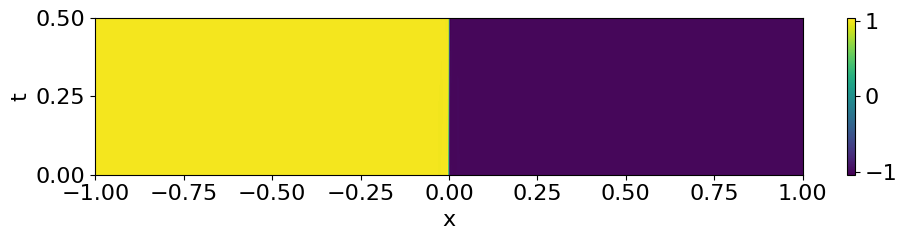

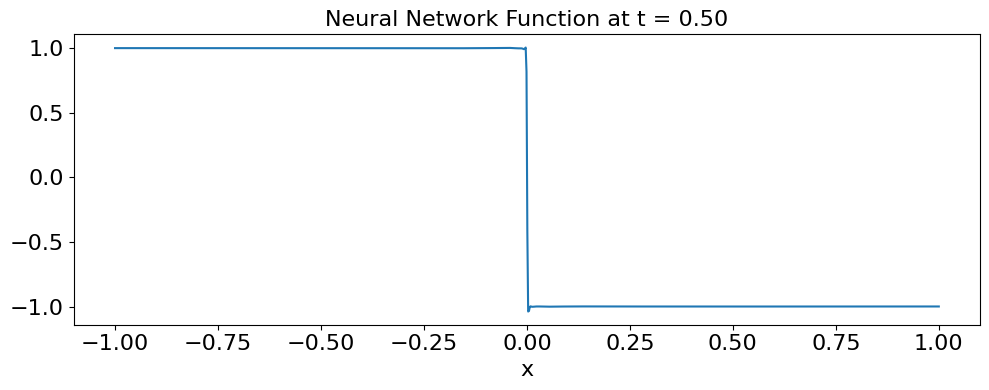


Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0


AttributeError: 'PiecewiseLinearPolynomials' object has no attribute 'quad_points_parti'

In [4]:
optProb.train_process_stage1(grade_epochs=[0])

In [5]:
optProb.pwp.triangles.shape

(4096, 3, 2)

In [4]:
vertices_all = optProb.pwp.triangles
params = optProb.model.mlps[0].params
Nt = optProb.pwp.N_elements
u_values_all = optProb.u_eval(params, vertices_all.reshape(-1, 2)).reshape(Nt, 3)
A_all = jnp.stack([jnp.ones((Nt, 3)), vertices_all[:, :, 0], vertices_all[:, :, 1]], axis=-1)
init_coeffs_all = jnp.linalg.solve(A_all, u_values_all[..., None]).squeeze(-1)

In [15]:
Nt = optProb.pwp.N_elements
vertices_all = optProb.pwp.triangles
u_values_all = optProb.u_eval(params, vertices_all.reshape(-1, 2)).reshape(Nt, 3)
avg_vals = jnp.average(u_values_all, axis=1)

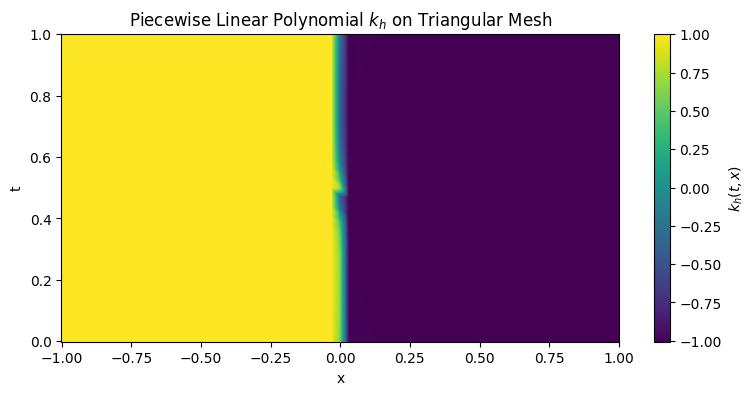

In [16]:
plot_kh(optProb.pwp)

In [41]:
optProb.N_perturb = 100000
optProb.sigma=1
optProb.pwp.coeffs, optProb.key, loss_eqn_from_kh, loss_eqn_abs = optProb.maximize_kh_step(params, optProb.key)

In [44]:
pwp_coef = jax.numpy.copy(optProb.pwp.coeffs)

(320, 640)


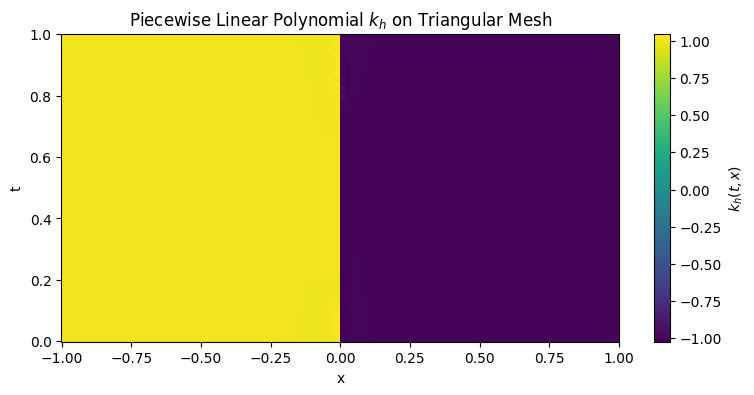

In [45]:
mid_pnts = jnp.average(vertices_all, axis=1)
mid_vals = optProb.u_eval(params, mid_pnts)
init_coeffs_all = jnp.hstack([mid_vals[..., None] , jnp.zeros((Nt, 2))])
optProb.pwp.coeffs = init_coeffs_all
plot_kh(optProb.pwp)

In [46]:
optProb.pwp.coeffs = pwp_coef
plot_kh(optProb.pwp)

(320, 640)


XlaRuntimeError: INTERNAL: Buffer Definition Event: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error preparing computation: Out of memory allocating 314572800000 bytes.

In [38]:
def plot_kh(pwp, M_factor=10):
    """
    Plot the piecewise linear polynomial k_h over the domain [t_min, t_max] x [x_min, x_max]
    on a triangular mesh, using JAX for efficiency.

    Args:
        pwp: PiecewiseLinearPolynomials instance with N_t, N_x, t_min, t_max, x_min, x_max, and coeffs.
        M_factor: Factor to refine the plotting grid (default: 10).
    """
    # Retrieve ranges and grid parameters from pwp
    t_min, t_max = pwp.t_min, pwp.t_max
    x_min, x_max = pwp.x_min, pwp.x_max
    N_t, N_x = pwp.N_t, pwp.N_x
    tau = (t_max - t_min) / N_t  # Step size for t
    hx = (x_max - x_min) / N_x   # Step size for x

    # Create fine grid using JAX arrays
    M_t, M_x = N_t * M_factor, N_x * M_factor
    t_grid = jnp.linspace(t_min, t_max, M_t)
    x_grid = jnp.linspace(x_min, x_max, M_x)
    t, x = jnp.meshgrid(t_grid, x_grid, indexing='ij')  # Shapes: (M_t, M_x)

    # Flatten the grid for vectorized operations
    tx_points = jnp.stack([t.ravel(), x.ravel()], axis=1)  # Shape: (M_t * M_x, 2)

    # Function to find the element index for a single point
    def find_element(tx):
        t_val, x_val = tx
        # Find the rectangle containing the point
        i = jnp.floor((t_val - t_min) / tau).astype(int)
        j = jnp.floor((x_val - x_min) / hx).astype(int)
        i = jnp.clip(i, 0, N_t - 1)
        j = jnp.clip(j, 0, N_x - 1)

        # Get vertices of the two triangles in this rectangle
        A = jnp.array([t_min + i * tau, x_min + j * hx])
        B = jnp.array([t_min + (i + 1) * tau, x_min + j * hx])
        C = jnp.array([t_min + i * tau, x_min + (j + 1) * hx])
        D = jnp.array([t_min + (i + 1) * tau, x_min + (j + 1) * hx])

        # Check which triangle contains the point
        in_triangle_1 = point_in_triangle(tx, A, B, C)
        in_triangle_2 = point_in_triangle(tx, B, D, C)
        global_idx = jnp.where(
            in_triangle_1,
            2 * (i * N_x + j),        # First triangle
            jnp.where(
                in_triangle_2,
                2 * (i * N_x + j) + 1,  # Second triangle
                -1                      # Not in any triangle
            )
        )
        return global_idx

    # Vectorize the find_element function over all points
    element_indices = vmap(find_element)(tx_points)  # Shape: (M_t * M_x,)

    # Evaluate k_h at all points using their corresponding element indices
    kh_values = pwp.evaluate(tx_points, element_indices)  # Shape: (M_t * M_x,)
    kh_values = kh_values.reshape(M_t, M_x)  # Reshape to (M_t, M_x)
    print(kh_values.shape)
    kh_values = np.asarray(kh_values)

    # Plot using pcolormesh
    height = int((t_max - t_min)*4)
    width = int((x_max - x_min)*4 + 1)
    plt.figure(figsize=(width, height))
    plt.pcolormesh(x_grid, t_grid, kh_values, shading='nearest', cmap='viridis')
    plt.colorbar(label='$k_h(t, x)$')
    plt.xlabel('x')
    plt.ylabel('t')
    plt.title('Piecewise Linear Polynomial $k_h$ on Triangular Mesh')
    plt.show()

In [40]:
p_temp = optProb.pwp.coeffs

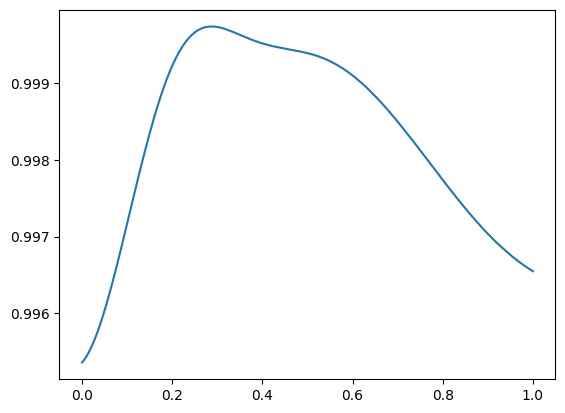

In [81]:
tt = jnp.linspace(0, 1, 1000)
c= -0.05
tx = jnp.hstack([tt[..., None], c*jnp.ones((1000,1))])
plt.plot(tt, optProb.u_eval(params, tx))

In [6]:
import jax.numpy as jnp
from jax import vmap
import numpy as np
from scipy import sparse

import flax.linen as nn
import optax.tree_utils as otu
from NN_class import MLP
# import mesh2D as mesh2D


class PiecewiseLinearPolynomialsRect:
    def __init__(self, N_t, N_x, t_min=0.0, t_max=1.0, x_min=-1.0, x_max=1.0, gauss_order=3, bdry_order=3):
        """
        Initialize piecewise linear polynomials on a rectangular mesh with custom ranges.

        Args:
            N_t: Number of divisions along the t-axis.
            N_x: Number of divisions along the x-axis.
            t_min: Minimum value for t (default: 0.0).
            t_max: Maximum value for t (default: 1.0).
            x_min: Minimum value for x (default: 0.0).
            x_max: Maximum value for x (default: 1.0).
            gauss_order: Order of Gauss quadrature (number of points per direction, default: 2).
            bdry_order: Order of boundary quadrature (number of points per edge, default: 3).
        """
        self.N_t = N_t
        self.N_x = N_x
        self.t_min = t_min
        self.t_max = t_max
        self.x_min = x_min
        self.x_max = x_max
        self.gauss_order = gauss_order
        self.bdry_order = bdry_order
        self.N_elements = N_t * N_x  # Number of rectangles
        self.partitions = self._generate_rectangles()
        self.coeffs = jnp.zeros((self.N_elements, 3))  # Coefficients a, b, c for a + b*t + c*x per rectangle
        self.quad_points, self.quad_weights, self.element_indices, self.quad_points_parti, self.quad_weights_parti = self._setup_quadrature()
        self.bdry_points_parti, self.bdry_weights_parti = self.get_boundary_quadrature()
        self.normals = self.compute_normals()

    def _generate_rectangles(self):
        """Generate the rectangles for the mesh with custom ranges."""
        tau = (self.t_max - self.t_min) / self.N_t  # Step size along t
        hx = (self.x_max - self.x_min) / self.N_x   # Step size along x
        rectangles = []
        for i in range(self.N_t):
            for j in range(self.N_x):
                rectangles.append(jnp.array([
                    [self.t_min + i * tau, self.x_min + j * hx],       # Bottom-left
                    [self.t_min + (i + 1) * tau, self.x_min + j * hx], # Top-left
                    [self.t_min + (i + 1) * tau, self.x_min + (j + 1) * hx], # Top-right
                    [self.t_min + i * tau, self.x_min + (j + 1) * hx]  # Bottom-right
                ]))
        return jnp.array(rectangles)

    def _setup_quadrature(self):
        """
        Setup Gauss quadrature points and weights for rectangular mesh.

        Returns:
            quad_points: Quadrature points, shape (N_quad, 2).
            quad_weights: Quadrature weights, shape (N_quad,).
            element_indices: Indices of rectangles, shape (N_quad,).
            quad_points_parti: Quadrature points per rectangle, shape (N_elements, Nq, 2).
            quad_weights_parti: Quadrature weights per rectangle, shape (N_elements, Nq).
        """
        Nq = self.gauss_order ** 2  # Number of quadrature points per rectangle

        # Gauss-Legendre nodes and weights in [-1, 1]
        nodes, weights = np.polynomial.legendre.leggauss(self.gauss_order)
        nodes_jnp = jnp.array(nodes)
        weights_jnp = jnp.array(weights)

        # Tensor product for 2D
        t_nodes, x_nodes = jnp.meshgrid(nodes_jnp, nodes_jnp)
        t_weights, x_weights = jnp.meshgrid(weights_jnp, weights_jnp)
        quad_weights_2d = (t_weights * x_weights).ravel()

        # Function to map [-1,1]x[-1,1] to rectangle [t_low, t_high]x[x_low, x_high]
        def map_to_rect(rect):
            t_low, x_low = rect[0]
            t_high, x_high = rect[2]
            t_scale = (t_high - t_low) / 2
            x_scale = (x_high - x_low) / 2
            t_center = (t_high + t_low) / 2
            x_center = (x_high + x_low) / 2
            t_points = t_center + t_nodes.ravel() * t_scale
            x_points = x_center + x_nodes.ravel() * x_scale
            points = jnp.stack([t_points, x_points], axis=1)
            weights = quad_weights_2d * (t_scale * x_scale)
            return points, weights

        # Vectorize over rectangles
        quad_points_rect, quad_weights_rect = vmap(map_to_rect)(self.partitions)

        # Flatten for global quadrature
        quad_points = quad_points_rect.reshape(-1, 2)
        quad_weights = quad_weights_rect.reshape(-1)
        element_indices = jnp.repeat(jnp.arange(self.N_elements), Nq)

        return quad_points, quad_weights, element_indices, quad_points_rect, quad_weights_rect

    def get_boundary_quadrature(self):
        """
        Generate Gauss-Legendre quadrature points and weights for the boundary of each rectangle.

        Returns:
            bdry_points_rect: Quadrature points for the boundaries, shape (N_elements, 4 * gauss_order, 2).
            bdry_weights_rect: Quadrature weights for the boundaries, shape (N_elements, 4 * gauss_order).
        """
        n = self.bdry_order  # Number of quadrature points per edge

        # Gauss-Legendre nodes and weights in [-1, 1]
        nodes, weights = np.polynomial.legendre.leggauss(n)
        nodes_jnp = jnp.array(nodes)
        weights_jnp = jnp.array(weights)

        # Function to compute quadrature for a single edge [v1, v2]
        def edge_quadrature(v1, v2):
            L = jnp.linalg.norm(v2 - v1) / 2  # Half-length for scaling
            direction = (v2 - v1) / (2 * L)  # Unit direction scaled
            center = (v1 + v2) / 2
            points = center + nodes_jnp[:, None] * L * direction
            weights_scaled = weights_jnp * L
            return points, weights_scaled

        # Vectorize the edge quadrature function over multiple edges
        edge_quadrature_vmap = vmap(edge_quadrature, in_axes=(0, 0))

        # Compute quadrature for each set of edges for all rectangles
        points_bottom, weights_bottom = edge_quadrature_vmap(self.partitions[:, 0], self.partitions[:, 3])  # Bottom: 0-3
        points_top, weights_top = edge_quadrature_vmap(self.partitions[:, 1], self.partitions[:, 2])  # Top: 1-2
        points_left, weights_left = edge_quadrature_vmap(self.partitions[:, 0], self.partitions[:, 1])  # Left: 0-1
        points_right, weights_right = edge_quadrature_vmap(self.partitions[:, 3], self.partitions[:, 2])  # Right: 3-2

        # Concatenate points and weights for all four edges per rectangle
        bdry_points_rect = jnp.concatenate([points_bottom, points_top, points_left, points_right], axis=1)  # Shape: (N_elements, 4*n, 2)
        bdry_weights_rect = jnp.concatenate([weights_bottom, weights_top, weights_left, weights_right], axis=1)  # Shape: (N_elements, 4*n)

        return bdry_points_rect, bdry_weights_rect

    def compute_normals(self):
        """Compute outward unit normals for each edge of each rectangle."""
        # Edges order: bottom, top, left, right
        # Normals: bottom (0, -1), top (0, 1), left (-1, 0), right (1, 0)
        normals = jnp.array([[0, -1], [0, 1], [-1, 0], [1, 0]])  # Fixed for all rectangles
        return jnp.tile(normals, (self.N_elements, 1, 1))  # Shape: (N_elements, 4, 2)

In [8]:
# Test function
def test_quadrature(N_t=2, N_x=3, t_min=0.0, t_max=2.0, x_min=-1.0, x_max=1.0, gauss_order=3, bdry_order=3):
    pwp = PiecewiseLinearPolynomialsRect(N_t, N_x, t_min, t_max, x_min, x_max, gauss_order=gauss_order, bdry_order=bdry_order)

    # Total area
    total_area = (t_max - t_min) * (x_max - x_min)

    # Test 1: Integrate f(t,x) = 1 (interior)
    integral_1 = np.sum(pwp.quad_weights)
    error_1 = abs(integral_1 - total_area)
    print(f"Interior Integral of 1: {integral_1:.10f}, Expected: {total_area}, Error: {error_1:.10f}")

    # Test 2: Integrate f(t,x) = t (interior)
    f_t = pwp.quad_points[:, 0]
    integral_t = np.sum(pwp.quad_weights * f_t)
    expected_t = ((t_max**2 - t_min**2)/2) * (x_max - x_min)
    error_t = abs(integral_t - expected_t)
    print(f"Interior Integral of t: {integral_t:.10f}, Expected: {expected_t}, Error: {error_t:.10f}")

    # Test 3: Integrate f(t,x) = x (interior)
    f_x = pwp.quad_points[:, 1]
    integral_x = np.sum(pwp.quad_weights * f_x)
    expected_x = ((x_max**2 - x_min**2)/2) * (t_max - t_min)
    error_x = abs(integral_x - expected_x)
    print(f"Interior Integral of x: {integral_x:.10f}, Expected: {expected_x}, Error: {error_x:.10f}")

    # Test 4: Integrate f(t,x) = t*x (interior)
    f_tx = pwp.quad_points[:, 0] * pwp.quad_points[:, 1]
    integral_tx = np.sum(pwp.quad_weights * f_tx)
    expected_tx = ((t_max**2 - t_min**2)/2) * ((x_max**2 - x_min**2)/2)
    error_tx = abs(integral_tx - expected_tx)
    print(f"Interior Integral of t*x: {integral_tx:.10f}, Expected: {expected_tx}, Error: {error_tx:.10f}")

    # Test 5: Integrate f(t,x) = t^2 (interior, to check higher order)
    f_t2 = pwp.quad_points[:, 0]**2
    integral_t2 = np.sum(pwp.quad_weights * f_t2)
    expected_t2 = ((t_max**3 - t_min**3)/3) * (x_max - x_min)
    error_t2 = abs(integral_t2 - expected_t2)
    print(f"Interior Integral of t^2: {integral_t2:.10f}, Expected: {expected_t2}, Error: {error_t2:.10f}")

    # Boundary quadrature test: Integrate g=1 over all "boundaries" (including internals, with multiplicity)
    # Calculated multiplicity: horizontal contributed lengths: 12 segments * hx = 12*(2/3)=8
    # Vertical: 12 segments * tau = 12*1=12 (for tau=1 with t_max=2, N_t=2)
    # Total 20
    hx = (x_max - x_min) / N_x
    tau = (t_max - t_min) / N_t
    num_horizontal_segments_contributed = N_t * N_x * 2  # Each rectangle contributes 2 horizontal
    total_horizontal_length = num_horizontal_segments_contributed * hx / 2  # Wait, no: each segment is hx long, but multiplicity already in contributed
    # From earlier calculation, for this setup, sum is 20.0
    integral_bdry_1 = np.sum(pwp.bdry_weights_parti)
    # Expected total contributed edge lengths
    # Horizontal: (N_t + 1) lines * N_x segments * hx, but with multiplicity: boundary lines 2 * N_x * hx, internal (N_t-1) * 2 * N_x * hx
    num_internal_horizontal_lines = N_t - 1
    total_horizontal = 2 * N_x * hx + 2 * num_internal_horizontal_lines * N_x * hx
    num_vertical_lines = N_x + 1
    num_vertical_segments_per_line = N_t
    boundary_vertical = 2 * num_vertical_segments_per_line * tau
    internal_vertical = (num_vertical_lines - 2) * 2 * num_vertical_segments_per_line * tau
    total_vertical = boundary_vertical + internal_vertical
    expected_bdry = total_horizontal + total_vertical
    error_bdry = abs(integral_bdry_1 - expected_bdry)
    print(f"Boundary Integral of 1: {integral_bdry_1:.10f}, Expected (multiplicity): {expected_bdry}, Error: {error_bdry:.10f}")

test_quadrature()

Interior Integral of 1: 4.0000004768, Expected: 4.0, Error: 0.0000004768
Interior Integral of t: 4.0000004768, Expected: 4.0, Error: 0.0000004768
Interior Integral of x: -0.0000000373, Expected: 0.0, Error: 0.0000000373
Interior Integral of t*x: -0.0000000261, Expected: 0.0, Error: 0.0000000261
Interior Integral of t^2: 5.3333339691, Expected: 5.333333333333333, Error: 0.0000004768
Boundary Integral of 1: 20.0000038147, Expected (multiplicity): 20.0, Error: 0.0000038147


In [18]:
# Gauss-Legendre nodes and weights in [-1, 1]
nodes, weights = np.polynomial.legendre.leggauss(3)
nodes_jnp = jnp.array(nodes)
weights_jnp = jnp.array(weights)
t_nodes, x_nodes = jnp.meshgrid(nodes_jnp, nodes_jnp)
t_weights, x_weights = jnp.meshgrid(weights_jnp, weights_jnp)
quad_weights_2d = (t_weights * x_weights).ravel()

In [11]:
import jax
import jax.numpy as jnp

def u(tx):
    t = tx[0]
    x = tx[1]
    return jnp.sin(2*t) + x**3

u_batch = jax.vmap(u)

In [12]:
pwp = PiecewiseLinearPolynomialsRect(N_t=10, N_x=10, t_min=0.0, t_max=2, x_min=-1.0, x_max=2)
quad_points = pwp.quad_points
quad_weights = pwp.quad_weights
u_batch(quad_points)@quad_weights

Array(9.980466, dtype=float32)

In [13]:
import scipy.integrate as integrate

def integrate_u_dblquad():
    """
    Integrate u(t, x) = sin(2t) + x^3 over [0, 2] x [-1, 1] using scipy.integrate.dblquad.
    Returns:
        integral: Numerical value of the integral.
        error: Estimated absolute error.
    """
    def u_scipy(t, x):
        return np.sin(2*t) + x**3  # SciPy requires NumPy arrays
    integral, error = integrate.dblquad(u_scipy, -1, 2, lambda x: 0, lambda x: 2)
    expected = 9.980466
    print(f"Double Integral of u(t,x) = sin(2t) + x^3: {integral:.10f}")
    print(f"Expected Value: {expected:.10f}")
    print(f"Absolute Error: {abs(integral - expected):.10f}")
    return integral, error

In [66]:
integral, error = integrate_u_dblquad()

Double Integral of u(t,x) = sin(2t) + x^3: 9.9804654313
Expected Value: 9.9804660000
Absolute Error: 0.0000005687
